# 4. Primeras estrategias para escapar de los óptimos locales

El capítulo 3 mostró que la búsqueda local se detiene en el primer óptimo local que encuentra y que cuál encuentra depende del punto de partida. Este capítulo presenta cuatro maneras sencillas de seguir buscando después de ese primer óptimo local. Los reinicios aleatorios repiten la búsqueda local desde puntos de partida distintos. La búsqueda local iterada perturba el óptimo local encontrado y vuelve a aplicar la búsqueda local. La aceptación de empeoramientos deja que la búsqueda se mueva, de vez en cuando, a un vecino peor. GRASP construye cada punto de partida con una heurística voraz aleatorizada. Al final, las cuatro estrategias se comparan con la búsqueda local simple en los tres problemas, con el mismo número de evaluaciones.

In [1]:
import math
import random
import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

## Los tres problemas con una interfaz común

Para aplicar cada estrategia a los tres problemas con el mismo código, cada problema se escribe como una clase con los mismos métodos:

- `aleatoria` genera una solución inicial al azar, como en el capítulo 3;
- `costo` evalúa una solución, y en la mochila es el valor con signo cambiado;
- `movimientos` devuelve todos los movimientos del vecindario en orden aleatorio, y `movimiento_aleatorio`, uno solo escogido al azar;
- `delta` calcula cuánto cambia el costo con un movimiento, y en la mochila devuelve `None` si el vecino no cabe;
- `aplicar` devuelve la solución vecina;
- `perturbar` y `construir_grasp` sirven a la búsqueda local iterada y a GRASP, y se explican en sus secciones.

Los vecindarios son los del capítulo 3, *flip* e intercambio en la mochila, intercambio de filas en las reinas y 2-opt en el agente viajero. Las instancias también son las mismas, la mochila de 20 objetos, el tablero de $30 \times 30$ y las 50 ciudades.

In [2]:
np.random.seed(42)
random.seed(42)

# Mismas instancias de los capítulos 1 y 3
N_OBJETOS = 20
pesos = np.random.randint(1, 31, size=N_OBJETOS)
valores = np.random.randint(1, 51, size=N_OBJETOS)
capacidad = int(0.4 * pesos.sum())
OPTIMO_MOCHILA = 402  # Por enumeración, capítulo 1

N_CIUDADES = 50
ciudades = np.random.uniform(0, 100, size=(N_CIUDADES, 2))
distancias = np.sqrt(((ciudades[:, None, :] - ciudades[None, :, :]) ** 2).sum(axis=2))

In [3]:
class Mochila:
    """Mochila 0-1. Costo: valor con signo cambiado. Movimientos: flip e intercambio."""

    def __init__(self, pesos, valores, capacidad):
        self.pesos, self.valores, self.capacidad = pesos, valores, capacidad
        self.n = len(pesos)

    def aleatoria(self):
        x = np.zeros(self.n, dtype=int)
        peso = 0
        for i in np.random.permutation(self.n):
            if np.random.random() < 0.5 and peso + self.pesos[i] <= self.capacidad:
                x[i] = 1
                peso += self.pesos[i]
        return x

    def costo(self, x):
        return -int(np.dot(x, self.valores))

    def movimientos(self, x):
        dentro, fuera = np.flatnonzero(x == 1), np.flatnonzero(x == 0)
        movs = [('flip', i) for i in range(self.n)] + [('swap', i, j) for i in dentro for j in fuera]
        random.shuffle(movs)
        return movs

    def movimiento_aleatorio(self, x):
        """Un movimiento al azar, uniforme entre los flip y los intercambios posibles."""
        dentro, fuera = np.flatnonzero(x == 1), np.flatnonzero(x == 0)
        r = random.randrange(self.n + len(dentro) * len(fuera))
        if r < self.n:
            return ('flip', r)
        r -= self.n
        return ('swap', dentro[r // len(fuera)], fuera[r % len(fuera)])

    def delta(self, x, mov):
        """Cambio en el costo, o None si el vecino no cabe en la mochila."""
        peso = np.dot(x, self.pesos)
        if mov[0] == 'flip':
            i = mov[1]
            signo = 1 if x[i] == 0 else -1
            if peso + signo * self.pesos[i] > self.capacidad:
                return None
            return -signo * self.valores[i]
        _, i, j = mov
        if peso - self.pesos[i] + self.pesos[j] > self.capacidad:
            return None
        return self.valores[i] - self.valores[j]

    def aplicar(self, x, mov):
        y = x.copy()
        if mov[0] == 'flip':
            y[mov[1]] = 1 - y[mov[1]]
        else:
            y[mov[1]], y[mov[2]] = 0, 1
        return y

    def perturbar(self, x, k=3):
        """Cambia k objetos al azar y luego saca objetos al azar hasta que la mochila quepa."""
        y = x.copy()
        for i in np.random.choice(self.n, size=k, replace=False):
            y[i] = 1 - y[i]
        while np.dot(y, self.pesos) > self.capacidad:
            y[np.random.choice(np.flatnonzero(y == 1))] = 0
        return y

    def construir_grasp(self, alfa):
        """Construcción voraz aleatorizada: elige al azar entre los objetos de mejor razón valor/peso."""
        x = np.zeros(self.n, dtype=int)
        peso = 0
        while True:
            candidatos = [i for i in range(self.n) if x[i] == 0 and peso + self.pesos[i] <= self.capacidad]
            if not candidatos:
                return x
            razon = {i: self.valores[i] / self.pesos[i] for i in candidatos}
            r_max, r_min = max(razon.values()), min(razon.values())
            lrc = [i for i in candidatos if razon[i] >= r_max - alfa * (r_max - r_min)]
            i = random.choice(lrc)
            x[i] = 1
            peso += self.pesos[i]

In [4]:
class Reinas:
    """n reinas sobre permutaciones. Costo: pares en conflicto. Movimiento: intercambio de dos filas."""

    def __init__(self, n):
        self.n = n

    def aleatoria(self):
        return list(np.random.permutation(self.n))

    def costo(self, s):
        diag1 = Counter(i - f for i, f in enumerate(s))
        diag2 = Counter(i + f for i, f in enumerate(s))
        return sum(c * (c - 1) // 2 for c in diag1.values()) + sum(c * (c - 1) // 2 for c in diag2.values())

    def movimientos(self, s):
        movs = [(i, j) for i in range(self.n - 1) for j in range(i + 1, self.n)]
        random.shuffle(movs)
        return movs

    def movimiento_aleatorio(self, s):
        return tuple(sorted(random.sample(range(self.n), 2)))

    def delta(self, s, mov):
        return self.costo(self.aplicar(s, mov)) - self.costo(s)

    def aplicar(self, s, mov):
        t = list(s)
        i, j = mov
        t[i], t[j] = t[j], t[i]
        return t

    def perturbar(self, s, k=3):
        """Aplica k intercambios de filas al azar."""
        t = list(s)
        for _ in range(k):
            i, j = random.sample(range(self.n), 2)
            t[i], t[j] = t[j], t[i]
        return t

    def construir_grasp(self, alfa):
        """Columna por columna, elige al azar entre las filas libres con pocos ataques."""
        s, libres = [], set(range(self.n))
        for col in range(self.n):
            ataques = {f: sum(1 for c, g in enumerate(s) if abs(g - f) == col - c) for f in libres}
            a_min, a_max = min(ataques.values()), max(ataques.values())
            lrc = [f for f in libres if ataques[f] <= a_min + alfa * (a_max - a_min)]
            f = random.choice(lrc)
            s.append(f)
            libres.remove(f)
        return s

In [5]:
class Viajero:
    """Agente viajero. Costo: longitud del recorrido. Movimiento: 2-opt."""

    def __init__(self, distancias):
        self.d = distancias
        self.n = len(distancias)

    def aleatoria(self):
        return list(np.random.permutation(self.n))

    def costo(self, ruta):
        return sum(self.d[ruta[k], ruta[(k + 1) % self.n]] for k in range(self.n))

    def movimientos(self, ruta):
        movs = [(i, j) for i in range(self.n - 1) for j in range(i + 2, self.n) if not (i == 0 and j == self.n - 1)]
        random.shuffle(movs)
        return movs

    def movimiento_aleatorio(self, ruta):
        while True:
            i, j = sorted(random.sample(range(self.n), 2))
            if j >= i + 2 and not (i == 0 and j == self.n - 1):
                return (i, j)

    def delta(self, ruta, mov):
        i, j = mov
        a, b, c, d = ruta[i], ruta[i + 1], ruta[j], ruta[(j + 1) % self.n]
        return self.d[a, c] + self.d[b, d] - self.d[a, b] - self.d[c, d]

    def aplicar(self, ruta, mov):
        i, j = mov
        return ruta[:i + 1] + ruta[i + 1:j + 1][::-1] + ruta[j + 1:]

    def perturbar(self, ruta, k=None):
        """Doble puente: corta el recorrido en cuatro tramos A B C D y los une como A C B D."""
        p1, p2, p3 = sorted(random.sample(range(1, self.n), 3))
        return ruta[:p1] + ruta[p2:p3] + ruta[p1:p2] + ruta[p3:]

    def construir_grasp(self, alfa):
        """Vecino más cercano aleatorizado, desde una ciudad al azar."""
        ruta = [random.randrange(self.n)]
        pendientes = set(range(self.n)) - {ruta[0]}
        while pendientes:
            dist = {j: self.d[ruta[-1], j] for j in pendientes}
            d_min, d_max = min(dist.values()), max(dist.values())
            lrc = [j for j in pendientes if dist[j] <= d_min + alfa * (d_max - d_min)]
            j = random.choice(lrc)
            ruta.append(j)
            pendientes.remove(j)
        return ruta


mochila = Mochila(pesos, valores, capacidad)
reinas = Reinas(30)
viajero = Viajero(distancias)

Las estrategias del capítulo se comparan con un presupuesto fijo de evaluaciones, contado como el número de vecinos cuyo cambio en el costo se calcula. La clase `Presupuesto` lleva esa cuenta. La búsqueda local de primera mejora del capítulo 3, reescrita sobre la interfaz común, se detiene en un óptimo local o cuando el presupuesto se agota. Se usa la primera mejora porque, según el capítulo 3, cuesta varias veces menos evaluaciones que la mejor mejora y da resultados parecidos.

In [6]:
class Presupuesto:
    """Cuenta las evaluaciones de vecinos y avisa cuando se agotan."""

    def __init__(self, maximo):
        self.maximo, self.usadas = maximo, 0

    def gastar(self, k=1):
        self.usadas += k

    @property
    def agotado(self):
        return self.usadas >= self.maximo


def busqueda_local(prob, x, presupuesto):
    """Primera mejora: se mueve al primer vecino que mejora, hasta un óptimo local o hasta agotar el presupuesto."""
    c = prob.costo(x)
    while not presupuesto.agotado:
        mejoro = False
        for mov in prob.movimientos(x):
            if presupuesto.agotado:
                break
            d = prob.delta(x, mov)
            presupuesto.gastar()
            if d is not None and d < -1e-9:
                x, c = prob.aplicar(x, mov), c + d
                mejoro = True
                break
        if not mejoro:
            break
    return x, c

## Reinicios aleatorios

La estrategia más simple para no depender de un solo punto de partida es repetir la búsqueda local desde muchos, cada uno generado al azar, y quedarse con el mejor óptimo local. Se conoce como reinicios aleatorios o multiarranque (*random restarts*, *multi-start*) y es la versión con búsqueda local del muestreo aleatorio del capítulo 1. Cada reinicio empieza de cero y no aprovecha nada de los óptimos locales anteriores.

In [7]:
def reinicios_aleatorios(prob, presupuesto):
    """Repite la búsqueda local desde soluciones aleatorias y guarda la mejor."""
    mejor_x, mejor_c, historia = None, math.inf, []
    while not presupuesto.agotado:
        x, c = busqueda_local(prob, prob.aleatoria(), presupuesto)
        if c < mejor_c:
            mejor_x, mejor_c = x, c
        historia.append((presupuesto.usadas, mejor_c))
    return mejor_x, mejor_c, historia

## Búsqueda local iterada

La búsqueda local iterada (*iterated local search*, ILS) parte de una suposición contraria, que los óptimos locales buenos están cerca de otros óptimos locales buenos. En lugar de empezar de cero, perturba el óptimo local actual con un cambio mayor que un movimiento del vecindario y aplica la búsqueda local al resultado. Si el nuevo óptimo local no es peor que el actual, lo reemplaza; si es peor, la búsqueda vuelve a perturbar el actual. La perturbación tiene que ser lo bastante grande para salir del valle del óptimo local actual y lo bastante pequeña para que la búsqueda no se convierta en reinicios aleatorios. Las perturbaciones de cada problema son las siguientes:

- en la mochila, cambiar el estado de tres objetos al azar y, si la selección no cabe, sacar objetos al azar hasta que quepa;
- en las reinas, aplicar tres intercambios de filas al azar;
- en el agente viajero, el doble puente (*double bridge*), que corta el recorrido en cuatro tramos $A\,B\,C\,D$ y los une en el orden $A\,C\,B\,D$, un cambio que 2-opt no deshace con un solo movimiento.

Como acepta un óptimo local igual al actual, la búsqueda se puede desplazar por mesetas como las de las reinas.

In [8]:
def busqueda_local_iterada(prob, presupuesto):
    """Perturba el óptimo local actual, aplica búsqueda local y acepta el resultado si no empeora."""
    x, c = busqueda_local(prob, prob.aleatoria(), presupuesto)
    mejor_x, mejor_c, historia = x, c, [(presupuesto.usadas, c)]
    while not presupuesto.agotado:
        y, cy = busqueda_local(prob, prob.perturbar(x), presupuesto)
        if cy <= c:
            x, c = y, cy
            if c < mejor_c:
                mejor_x, mejor_c = x, c
        historia.append((presupuesto.usadas, mejor_c))
    return mejor_x, mejor_c, historia

## Caminata aleatoria y aceptación de empeoramientos

Otra manera de salir de un óptimo local es moverse, a veces, a un vecino peor. La función `aceptacion_fija` evalúa en cada paso un vecino escogido al azar y lo acepta si no empeora la solución; si la empeora, lo acepta con una probabilidad fija $p$. Con $p = 1$ acepta todo y es una caminata aleatoria (*random walk*), que recorre el espacio de soluciones sin preferir las buenas. Con $p = 0$ solo acepta vecinos iguales o mejores. A diferencia de la búsqueda local del capítulo 3, puede moverse a un vecino de igual costo y no se detiene en un óptimo local, porque sigue probando vecinos al azar hasta agotar el presupuesto. La figura siguiente muestra el costo de la solución actual con $p = 0$, 0,1 y 1 en el tablero de $30 \times 30$, durante 20 000 pasos.

In [9]:
def aceptacion_fija(prob, presupuesto, p):
    """
    En cada paso evalúa un vecino al azar. Lo acepta si no empeora la solución
    y, si la empeora, con probabilidad fija p. Con p = 1 es una caminata aleatoria.
    """
    x = prob.aleatoria()
    c = prob.costo(x)
    mejor_x, mejor_c = x, c
    actual, historia = [], []
    while not presupuesto.agotado:
        mov = prob.movimiento_aleatorio(x)
        d = prob.delta(x, mov)  # None si el vecino es infactible (mochila)
        presupuesto.gastar()
        if d is not None and (d <= 0 or random.random() < p):
            x, c = prob.aplicar(x, mov), c + d
            if c < mejor_c:
                mejor_x, mejor_c = x, c
        actual.append(c)
        historia.append((presupuesto.usadas, mejor_c))
    return mejor_x, mejor_c, historia, actual

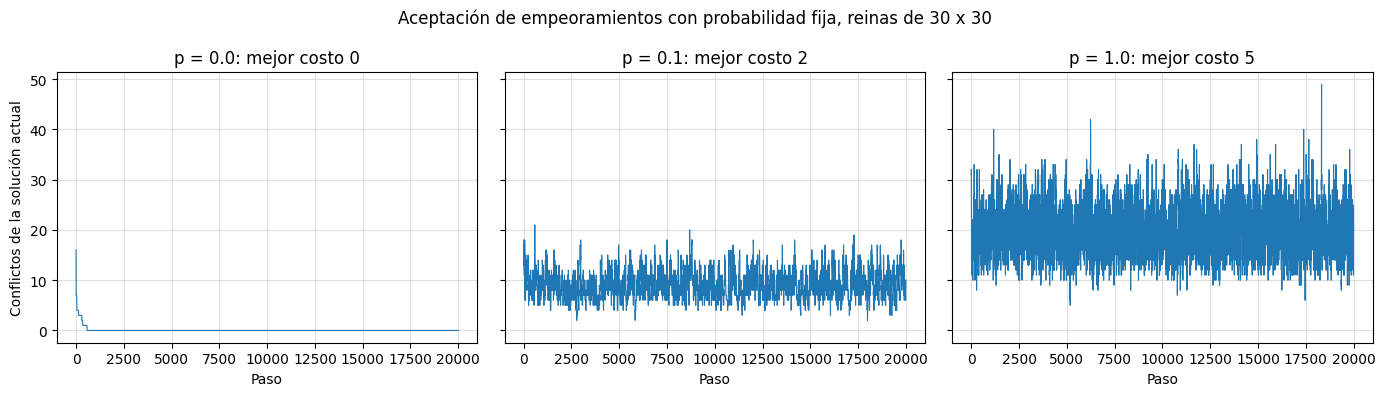

In [10]:
random.seed(42)
np.random.seed(42)
fig, ejes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for eje, p in zip(ejes, [0.0, 0.1, 1.0]):
    _, mejor_c, _, actual = aceptacion_fija(reinas, Presupuesto(20000), p)
    eje.plot(actual, linewidth=0.8)
    eje.set_title(f'p = {p}: mejor costo {mejor_c}')
    eje.set_xlabel('Paso')
    eje.grid(True, alpha=0.4)
ejes[0].set_ylabel('Conflictos de la solución actual')
plt.suptitle('Aceptación de empeoramientos con probabilidad fija, reinas de 30 x 30')
plt.tight_layout()
plt.show()

Con $p = 0$ la búsqueda llega a cero conflictos en unos cientos de pasos. Aceptar vecinos de igual costo le basta para cruzar las mesetas en las que se detenía la búsqueda local del capítulo 3. Con $p = 0{,}1$ la solución actual oscila alrededor de 10 conflictos y la mejor solución se queda en 2. Casi todos los vecinos de una solución buena son peores, y al aceptar uno de cada diez la búsqueda se aleja de la zona buena tan rápido como se acerca. Con $p = 1$ el costo oscila alrededor de 20 conflictos, cerca del promedio de una permutación al azar, que es $(2n-1)/3 \approx 19{,}7$ con $n = 30$, y la mejor solución tiene 5.

La celda siguiente repite el experimento con varias probabilidades en las reinas y en el agente viajero, con 8 semillas, y muestra el promedio del mejor costo.

In [11]:
probabilidades = [0.0, 0.001, 0.01, 0.05, 0.1]
print(f"{'problema':<8} | " + " | ".join(f"p = {p:<5}" for p in probabilidades))
for nombre, prob, max_eval in [('Reinas', reinas, 20000), ('Viajero', viajero, 100000)]:
    promedios = []
    for p in probabilidades:
        mejores = []
        for semilla in range(8):
            random.seed(semilla)
            np.random.seed(semilla)
            mejores.append(aceptacion_fija(prob, Presupuesto(max_eval), p)[1])
        promedios.append(np.mean(mejores))
    print(f"{nombre:<8} | " + " | ".join(f"{m:>9.2f}" for m in promedios))

problema | p = 0.0   | p = 0.001 | p = 0.01  | p = 0.05  | p = 0.1  


Reinas   |      0.00 |      0.00 |      0.00 |      1.62 |      1.62


Viajero  |    605.01 |    570.18 |    681.05 |    941.20 |   1097.28


En las reinas, cualquier probabilidad de hasta 0,01 llega a cero conflictos en las 8 semillas, y desde 0,05 la búsqueda ya no lo logra. En el agente viajero el margen es mucho más estrecho. Con $p = 0$ la búsqueda queda en 605,01 en promedio, con $p = 0{,}001$ mejora a 570,18 y con $p = 0{,}01$ empeora a 681,05. La probabilidad adecuada depende del problema, y una probabilidad fija trata igual un empeoramiento pequeño y uno grande. El recocido simulado del capítulo 7 corrige las dos cosas, porque hace que la probabilidad de aceptar dependa de cuánto empeora el vecino y de una temperatura que baja durante la búsqueda. La comparación de la sección final usa $p = 0{,}001$, el mejor valor de este barrido, que se hizo sobre las mismas instancias; eso favorece a esta estrategia en la comparación.

## GRASP

GRASP (*greedy randomized adaptive search procedure*) repite dos fases hasta agotar el presupuesto, una construcción voraz aleatorizada y una búsqueda local desde la solución construida, y se queda con el mejor óptimo local. La construcción es la de la heurística constructiva del capítulo 3, con una diferencia. En cada paso, en lugar de escoger el mejor candidato, arma una lista restringida de candidatos (*restricted candidate list*, RCL) con los candidatos cuya evaluación $g$ está cerca de la mejor y escoge uno al azar. Si se minimiza $g$, la lista es

$$\text{RCL} = \{\, c : g(c) \le g_{\min} + \alpha\,(g_{\max} - g_{\min}) \,\},$$

y si se maximiza, la condición es $g(c) \ge g_{\max} - \alpha\,(g_{\max} - g_{\min})$. Con $\alpha = 0$ la construcción es la voraz y con $\alpha = 1$ es aleatoria; el capítulo usa $\alpha = 0{,}3$. La evaluación $g$ de cada problema es la de su heurística constructiva:

- en la mochila, la razón de valor por peso de los objetos que caben;
- en las reinas, el número de ataques de cada fila libre a las reinas ya ubicadas;
- en el agente viajero, la distancia desde la última ciudad del recorrido, que parte de una ciudad al azar.

Frente a los reinicios aleatorios, GRASP empieza la búsqueda local desde soluciones que son buenas y variadas a la vez. Cada solución construida cuenta como una evaluación del presupuesto.

In [12]:
def grasp(prob, presupuesto, alfa=0.3):
    """Construcción voraz aleatorizada seguida de búsqueda local, repetida hasta agotar el presupuesto."""
    mejor_x, mejor_c, historia = None, math.inf, []
    while not presupuesto.agotado:
        x0 = prob.construir_grasp(alfa)
        presupuesto.gastar()  # La solución construida cuenta como una evaluación
        x, c = busqueda_local(prob, x0, presupuesto)
        if c < mejor_c:
            mejor_x, mejor_c = x, c
        historia.append((presupuesto.usadas, mejor_c))
    return mejor_x, mejor_c, historia

## Comparación

La celda siguiente aplica las cuatro estrategias y la búsqueda local simple a los tres problemas, con 20 semillas por combinación. El presupuesto es de 5000 evaluaciones en la mochila, 20 000 en las reinas y 100 000 en el agente viajero. La búsqueda local simple es una sola corrida de primera mejora desde una solución aleatoria y se detiene en su primer óptimo local, así que usa menos evaluaciones que el presupuesto. La tabla da, para cada combinación, el promedio, el mejor y el peor resultado de las 20 semillas (el valor en la mochila y el costo en los otros dos problemas), el número promedio de evaluaciones y el tiempo total.

In [13]:
def busqueda_local_simple(prob, presupuesto):
    x, c = busqueda_local(prob, prob.aleatoria(), presupuesto)
    return x, c, [(presupuesto.usadas, c)]


metodos = {
    'Búsqueda local': busqueda_local_simple,
    'Reinicios': reinicios_aleatorios,
    'ILS': busqueda_local_iterada,
    'Aceptación p = 0,001': lambda prob, pres: aceptacion_fija(prob, pres, 0.001)[:3],
    'GRASP': grasp,
}
problemas = {
    'Mochila (20 objetos)': (mochila, 5000),
    'Reinas (30 x 30)': (reinas, 20000),
    'Viajero (50 ciudades)': (viajero, 100000),
}
num_semillas = 20

resultados = {}
for nombre_prob, (prob, max_eval) in problemas.items():
    for nombre_met, metodo in metodos.items():
        inicio = time.perf_counter()
        costos, usadas = [], []
        for semilla in range(num_semillas):
            random.seed(semilla)
            np.random.seed(semilla)
            pres = Presupuesto(max_eval)
            _, c, _ = metodo(prob, pres)
            costos.append(c)
            usadas.append(pres.usadas)
        resultados[(nombre_prob, nombre_met)] = (costos, usadas, time.perf_counter() - inicio)

for nombre_prob, (prob, max_eval) in problemas.items():
    signo = -1 if nombre_prob.startswith('Mochila') else 1  # La mochila se informa como valor
    print(f"{nombre_prob}, presupuesto de {max_eval:,d} evaluaciones, {num_semillas} semillas")
    print(f"  {'método':<20} | {'promedio':>9} | {'mejor':>8} | {'peor':>8} | {'evaluaciones':>12} | {'tiempo':>7}")
    for nombre_met in metodos:
        costos, usadas, t = resultados[(nombre_prob, nombre_met)]
        valores_m = [signo * c for c in costos]
        mejor, peor = (max(valores_m), min(valores_m)) if signo < 0 else (min(valores_m), max(valores_m))
        print(f"  {nombre_met:<20} | {np.mean(valores_m):>9.2f} | {mejor:>8.2f} | {peor:>8.2f} | "
              f"{np.mean(usadas):>12,.0f} | {t:>6.1f}s")
    print()

for nombre_met in metodos:
    costos = resultados[('Mochila (20 objetos)', nombre_met)][0]
    ceros = resultados[('Reinas (30 x 30)', nombre_met)][0]
    print(f"{nombre_met:<20}: óptimo de la mochila en {sum(-c == OPTIMO_MOCHILA for c in costos)} de {num_semillas}; "
          f"reinas sin conflictos en {sum(c == 0 for c in ceros)} de {num_semillas}")

Mochila (20 objetos), presupuesto de 5,000 evaluaciones, 20 semillas
  método               |  promedio |    mejor |     peor | evaluaciones |  tiempo
  Búsqueda local       |    399.00 |   402.00 |   382.00 |          286 |    0.0s
  Reinicios            |    402.00 |   402.00 |   402.00 |        5,000 |    0.3s
  ILS                  |    402.00 |   402.00 |   402.00 |        5,000 |    0.2s
  Aceptación p = 0,001 |    400.70 |   402.00 |   385.00 |        5,000 |    0.3s
  GRASP                |    402.00 |   402.00 |   402.00 |        5,000 |    0.2s

Reinas (30 x 30), presupuesto de 20,000 evaluaciones, 20 semillas
  método               |  promedio |    mejor |     peor | evaluaciones |  tiempo
  Búsqueda local       |      0.85 |     0.00 |     2.00 |          878 |    0.3s
  Reinicios            |      0.00 |     0.00 |     0.00 |       20,000 |    6.8s
  ILS                  |      0.00 |     0.00 |     0.00 |       20,000 |    6.5s
  Aceptación p = 0,001 |      0.00 |     0.0

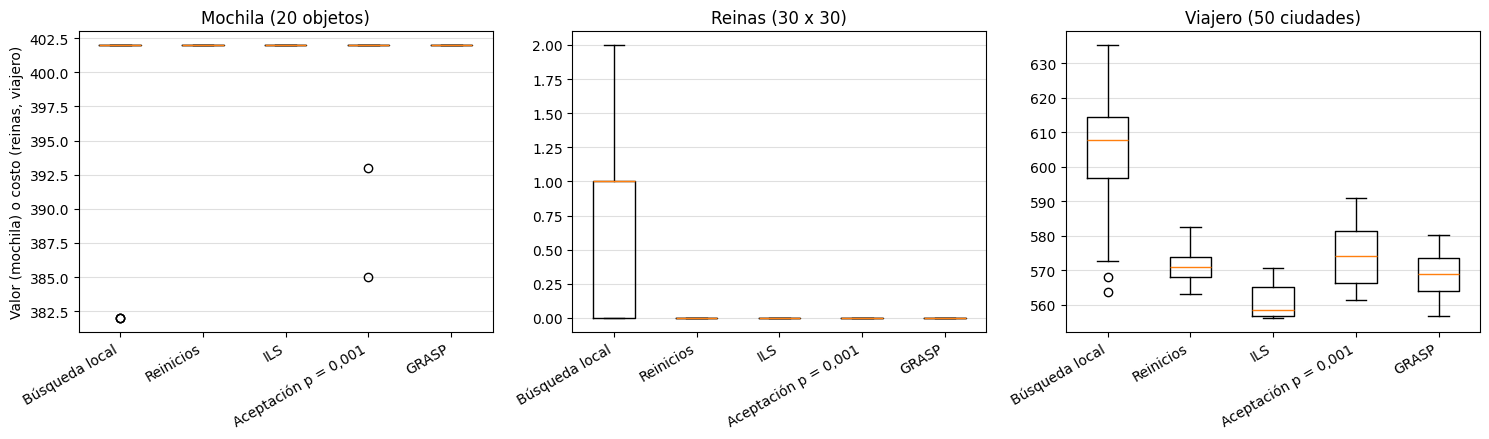

In [14]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))
for eje, (nombre_prob, (prob, _)) in zip(ejes, problemas.items()):
    signo = -1 if nombre_prob.startswith('Mochila') else 1
    datos = [[signo * c for c in resultados[(nombre_prob, m)][0]] for m in metodos]
    eje.boxplot(datos)
    eje.set_xticks(range(1, len(metodos) + 1))
    eje.set_xticklabels(list(metodos), rotation=30, ha='right')
    eje.set_title(nombre_prob)
    eje.grid(True, axis='y', alpha=0.4)
ejes[0].set_ylabel('Valor (mochila) o costo (reinas, viajero)')
plt.tight_layout()
plt.show()

En la mochila y en las reinas, las instancias resultan fáciles para las cuatro estrategias. Los reinicios, ILS y GRASP llegan al óptimo de la mochila y a un tablero sin conflictos en las 20 semillas, y la aceptación con $p = 0{,}001$ lo hace en las 20 semillas de las reinas y en 18 de la mochila. La búsqueda local simple, en cambio, se queda en un óptimo local en 3 de las 20 corridas de la mochila y en 13 de las 20 de las reinas, de modo que cualquiera de las cuatro estrategias basta para resolver estas dos instancias.

En el agente viajero las estrategias sí se separan. ILS obtiene el menor promedio, 560,73, y el mejor recorrido, 556,20, más corto que todos los óptimos locales del capítulo 3. Le siguen GRASP, con 568,54, y los reinicios y la aceptación con probabilidad fija, con 571,45 y 574,90. ILS también es la que menos tiempo toma con el mismo número de evaluaciones. En esta implementación, cada movimiento aceptado obliga a generar y barajar de nuevo la lista de vecinos; la búsqueda local que sigue a una perturbación acepta pocos movimientos, mientras que los reinicios aceptan muchos al bajar desde recorridos aleatorios. Con 20 semillas y una sola instancia por problema, estas diferencias son indicios y no conclusiones; el capítulo 16 presenta las pruebas estadísticas que hacen falta para comparar algoritmos.